# 04 · Proyectos de inversión: ¿en qué se gastó la plata?

**Proyecto:** ¿Acacías vive del petróleo? Regalías vs. desarrollo
**Fuente:** DNP, MapaInversiones → Reportes → Proyectos. Descarga del 24/11/2026, durante un mantenimiento de la plataforma (el DNP avisaba de posibles inconsistencias mientras sincronizaba las bases).
- **Datos Básicos** (`Reporte_Reporte_ProyectosDatosBásicos.xlsx`): proyectos cuya **entidad responsable es la Alcaldía de Acacías**. Trae valores, avance físico y financiero.
- **Localización** (`Reporte_DatosLocalizacion.csv`): proyectos **ubicados en Acacías**, sin importar quién los ejecuta. No trae valores.

**Preguntas**
1. ¿En qué sectores invirtió la alcaldía sus regalías?
2. ¿Cuánto se aprobó cada año?
3. ¿Hay proyectos que merezcan seguimiento (plazos vencidos, avance físico rezagado)?

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.max_colwidth", 80)

RAW = Path("../data/proyectos_sgr")
OUT = Path("../data processed")
ANIO_BASE = 2025

## 1. Datos Básicos

Problemas de formato:
- Los números vienen como **texto con coma decimal** (`'47278390455,21000000'`).
- El BPIN trae un **apóstrofo** al inicio (`'2021500060042`), un truco de Excel para que no lo convierta en número. Hay que quitarlo y guardarlo como texto.
- `HorizonteProyecto` viene como `'2022-2025'` y conviene separarlo en año de inicio y de fin.

In [2]:
basicos = pd.read_excel(RAW / "Reporte_Reporte_ProyectosDatosBásicos.xlsx", dtype=str)

basicos = basicos.rename(columns={
    "TipoBanco": "banco", "SectorProyecto": "sector", "EntidadResponsable": "entidad",
    "Ocad": "ocad", "Bpin": "bpin", "NombreProyecto": "nombre", "EstadoProyecto": "estado",
    "ValorTotalProyecto": "valor_total", "ValorSolicitadoProyecto": "valor_solicitado",
    "ValorEjecutadoProyecto": "valor_ejecutado", "AvanceFisico": "avance_fisico",
    "AvanceFinanciero": "avance_financiero", "HorizonteProyecto": "horizonte",
    "SubEstadoProyecto": "subestado", "Beneficiarios": "beneficiarios",
})

num = ["valor_total", "valor_solicitado", "valor_ejecutado", "avance_fisico", "avance_financiero", "beneficiarios"]
for c in num:
    basicos[c] = pd.to_numeric(basicos[c].str.replace(",", ".", regex=False), errors="coerce")

basicos["bpin"] = basicos["bpin"].str.lstrip("'").str.strip()
basicos["nombre"] = basicos["nombre"].str.replace(r"\s+", " ", regex=True).str.strip()
basicos[["anio_inicio", "anio_fin"]] = basicos["horizonte"].str.split("-", expand=True).astype(int)

print(basicos.shape, "| BPIN duplicados:", basicos["bpin"].duplicated().sum())
print(basicos["banco"].value_counts())
basicos.head(3)

(609, 17) | BPIN duplicados: 0
banco
TERRITORIAL    499
SGR            110
Name: count, dtype: int64


,banco,sector,entidad,ocad,bpin,nombre,estado,valor_total,valor_solicitado,valor_ejecutado,avance_fisico,avance_financiero,horizonte,subestado,beneficiarios,anio_inicio,anio_fin
0,TERRITORIAL,Salud Y Protección Social,"Acacías,Meta",NaN,2021500060042,Administración De Los Recursos Del Subcomponente Del Subsidio A La Oferta De...,Viable,0.0,0.0,0.0,0.0,0.0,2022-2022,Viable,2886,2022,2022
1,TERRITORIAL,Gobierno Territorial,"Acacías,Meta",NaN,2021500060043,Fortalecimiento De Las Acciones Para La Garantía Prevención Y Respeto De Los...,Viable,0.0,0.0,"108,911,665.0",0.0,0.0,2022-2022,Viable,93323,2022,2022
2,TERRITORIAL,Salud Y Protección Social,"Acacías,Meta",NaN,2021500060044,Fortalecimiento Del Acceso Y Permanencia En El Régimen Subsidiado En Salud A...,Viable,0.0,0.0,"47,278,390,455.2",0.0,0.0,2022-2022,Viable,39713,2022,2022


**Dos bancos de proyectos:**
- **SGR:** financiados con **regalías**. Es el foco del proyecto.
- **TERRITORIAL:** financiados con recursos propios del municipio. Sirven de contexto, pero muchos están en formulación o sin recursos asignados.

In [3]:
pd.crosstab(basicos["estado"], basicos["banco"], margins=True)

banco,SGR,TERRITORIAL,All
estado,,,
Desaprobado,10,0,10
En Ejecución,12,188,200
Formulación,14,156,170
Terminado,73,0,73
Viable,1,155,156
All,110,499,609


## 2. Localización: proyectos en Acacías de otras entidades

In [4]:
# El CSV viene en latin-1, con una primera línea 'sep=,' y una coma sobrante al final de cada fila
loc = pd.read_csv(RAW / "Reporte_DatosLocalizacion.csv", skiprows=1, encoding="latin-1", dtype=str, index_col=False)
loc.columns = ["tipo", "sector", "entidad", "bpin", "nombre", "region", "departamento", "municipio", "estado"]
loc["bpin"] = loc["bpin"].str.lstrip("'").str.strip()
loc["en_datos_basicos"] = loc["bpin"].isin(basicos["bpin"])

print(loc.shape)
print(loc["tipo"].value_counts(), "\n")
loc.groupby("entidad").size().sort_values(ascending=False).head(8)

(351, 10)
tipo
SGR    258
PGN     93
Name: count, dtype: int64 



entidad
Acacías,Meta                                                                                   108
Meta                                                                                           107
Unidad de Servicios Penitenciarios y Carcelarios - USPEC - Justicia y del Derecho               15
Asociación Afro de Acacias Meta Raizales y Palenqueros, Asafrodacam.                             8
Unidad de Atención y Reparación Integral a las Victimas - Inclusión Social y Reconciliación      6
Asociación Afrocolombiana de Campesinos y Trabajadores de Acacias, Afroacta                      6
Agencia de Desarrollo Rural - ADR - Agricultura y Desarrollo Rural                               5
Region del Llano                                                                                 5
dtype: int64

**Hallazgo importante:** de los 351 proyectos ubicados en Acacías, solo **108 son de la alcaldía** (y están en Datos Básicos). Hay unos **107 de la Gobernación del Meta** y otros de entidades nacionales que **no tienen valores** en nuestros datos.

➡️ **Para completar:** descargar *Datos Básicos* con *Entidad Responsable = Meta* (Gobernación) y unir por BPIN. Así sabremos cuánto invirtió el departamento dentro de Acacías.

In [5]:
(loc[~loc["en_datos_basicos"]]
   .pivot_table(index="sector", columns="tipo", values="bpin", aggfunc="count", fill_value=0)
   .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False).head(10))

tipo,PGN,SGR,total
sector,,,
"Vivienda, Ciudad Y Territorio",2,41,43
Inclusión Social Y Reconciliación,11,19,30
Educación,1,27,28
Agricultura Y Desarrollo Rural,10,16,26
Justicia Y Del Derecho,23,0,23
Transporte,4,7,11
"Ciencia, Tecnología E Innovación",0,10,10
Salud Y Protección Social,2,7,9
"Comercio, Industria Y Turismo",1,8,9


## 3. Inversión de regalías de la alcaldía

Se toman los proyectos **SGR** que llegaron a aprobarse: *Terminado*, *En Ejecución* o *Viable*. Se dejan por fuera los que están en *Formulación* o fueron *Desaprobados*.

Para comparar años, el valor se pasa a **pesos de 2025** usando el IPC del **año de inicio** del proyecto (una aproximación, porque un proyecto puede durar varios años).

In [6]:
ipc = pd.read_csv(OUT / "ipc_anual.csv").set_index("anio")[f"factor_a_pesos_{ANIO_BASE}"]

sgr = basicos[(basicos["banco"] == "SGR") & basicos["estado"].isin(["Terminado", "En Ejecución", "Viable"])].copy()
sgr["valor_total_const"] = sgr["valor_total"] * sgr["anio_inicio"].map(ipc)
sgr["valor_ejecutado_const"] = sgr["valor_ejecutado"] * sgr["anio_inicio"].map(ipc)

print(f"{len(sgr)} proyectos SGR aprobados")
print(f"Valor total: {sgr['valor_total_const'].sum() / 1e9:,.0f} mil millones de pesos de {ANIO_BASE}")
print(f"Ejecutado:   {sgr['valor_ejecutado_const'].sum() / 1e9:,.0f} mil millones de pesos de {ANIO_BASE}")

86 proyectos SGR aprobados
Valor total: 806 mil millones de pesos de 2025
Ejecutado:   700 mil millones de pesos de 2025


In [7]:
por_sector = (sgr.groupby("sector")
                 .agg(proyectos=("bpin", "count"), valor=("valor_total_const", "sum"))
                 .sort_values("valor", ascending=False))
por_sector["valor_mm"] = por_sector["valor"] / 1e9
por_sector["participacion_pct"] = 100 * por_sector["valor"] / por_sector["valor"].sum()
por_sector[["proyectos", "valor_mm", "participacion_pct"]]

,proyectos,valor_mm,participacion_pct
sector,,,
Transporte,26,343.1,42.6
"Vivienda, Ciudad Y Territorio",33,211.8,26.3
Educación,14,82.6,10.2
Gobierno Territorial,2,65.1,8.1
Deporte Y Recreación,6,28.8,3.6
"Comercio, Industria Y Turismo",1,25.6,3.2
Cultura,1,23.2,2.9
Tecnologías De La Información Y Las Comunicaciones,1,19.7,2.4
Minas Y Energía,1,4.7,0.6


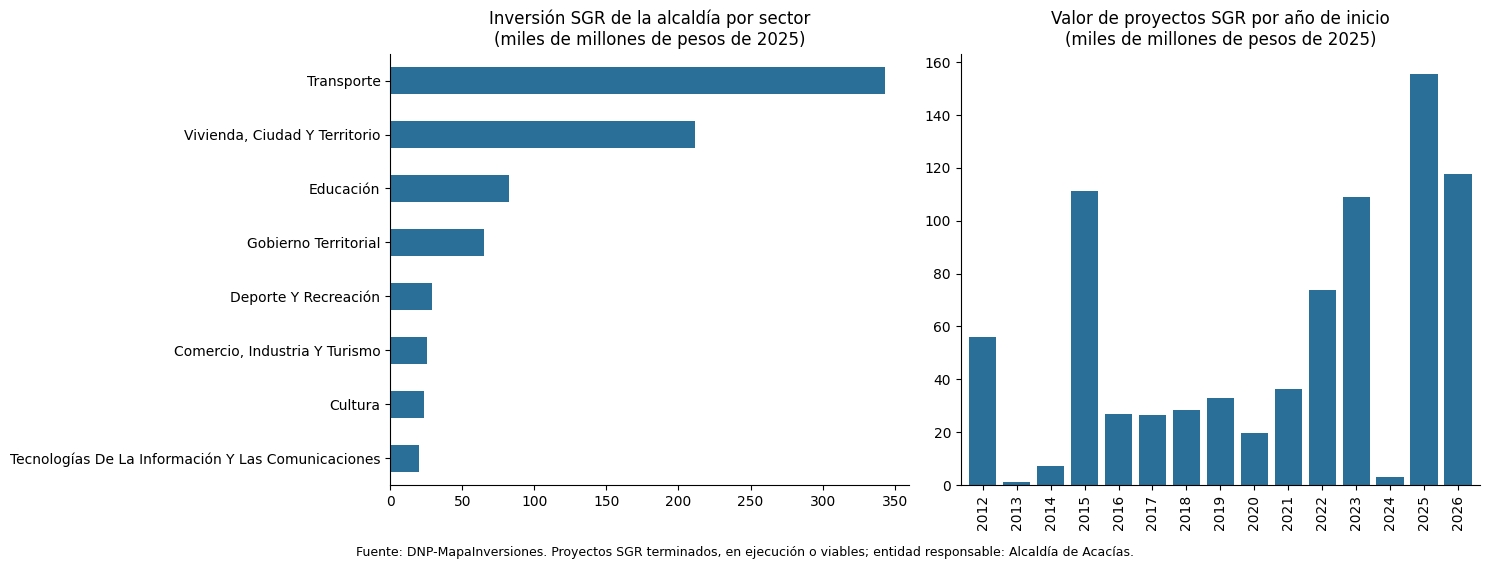

In [8]:
por_anio = sgr.groupby("anio_inicio")["valor_total_const"].sum().div(1e9).reindex(range(2012, 2027), fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

top = por_sector["valor_mm"].head(8).sort_values()
top.plot(kind="barh", ax=ax[0], color="#2a6f97")
ax[0].set_title(f"Inversión SGR de la alcaldía por sector\n(miles de millones de pesos de {ANIO_BASE})")
ax[0].set_ylabel("")

por_anio.plot(kind="bar", ax=ax[1], color="#2a6f97", width=0.8)
ax[1].set_title(f"Valor de proyectos SGR por año de inicio\n(miles de millones de pesos de {ANIO_BASE})")
ax[1].set_xlabel("")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Fuente: DNP-MapaInversiones. Proyectos SGR terminados, en ejecución o viables; entidad responsable: Alcaldía de Acacías.",
         ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Lecturas:**
- **Vías y vivienda/agua se llevan casi el 70%** de la inversión SGR de la alcaldía. Educación, alrededor del 10%.
- **Posible ciclo político:** los años de inicio de gobierno municipal (2016, 2020, 2024) tienen poca inversión nueva, y los últimos años de cada mandato se disparan. En Colombia los alcaldes gobiernan cuatro años (2016-2019, 2020-2023, 2024-2027). Es una hipótesis interesante para el análisis final.
- **¿Por qué el valor de los proyectos (unos 806 mil millones) supera lo recibido en Asignaciones Directas (unos 470 mil millones en pesos de 2025)?** Porque un proyecto puede cofinanciarse con otras fuentes del SGR (asignaciones regionales, departamentales) o con recursos propios.

### Los 10 proyectos más grandes

In [9]:
top10 = (sgr.nlargest(10, "valor_total_const")
            [["bpin", "nombre", "sector", "estado", "horizonte", "valor_total_const", "avance_fisico", "avance_financiero"]]
            .assign(valor_total_const=lambda d: d["valor_total_const"] / 1e9)
            .rename(columns={"valor_total_const": f"valor_mm_{ANIO_BASE}"})
            .reset_index(drop=True))
top10.index += 1
top10

,bpin,nombre,sector,estado,horizonte,valor_mm_2025,avance_fisico,avance_financiero
1,2026500060003,Mejoramiento Y Obras Complementarias De La Vía Terciaria Que Conduce Del Cen...,Transporte,En Ejecución,2026-2029,107.3,0.0,14.9
2,2025500060008,Construcción De La Alcaldia Del Municipio De Acacías Meta,Gobierno Territorial,En Ejecución,2025-2026,41.1,0.0,49.8
3,2025500060006,Mejoramiento Y Obras Complementarias De La Via Terciaria Que Conduce Del Sec...,Transporte,En Ejecución,2025-2026,36.8,0.0,49.8
4,2023500060021,Mejoramiento De Vías Urbanas En El Municipio De Acacías,Transporte,Terminado,2023-2023,33.5,99.7,99.7
5,2015005500039,Construcción De Vivienda De Interes Prioritario Urbanizacion Sierra Nevada P...,"Vivienda, Ciudad Y Territorio",Terminado,2015-2017,32.2,100.0,91.0
6,2015500060008,"Construcción De Vias En Concreto Rigido, Redes De Alcantarillado Y Obras Com...",Transporte,Terminado,2015-2019,27.1,100.0,90.8
7,2016500060001,Construcción De La Institucion Educativa Juan Humberto Baquero Soler Sede El...,Educación,Terminado,2016-2019,27.1,100.0,92.0
8,2025500060004,Construcción De La Arena Mayor Del Centro Cultural Autoctono Y Turistico Del...,"Comercio, Industria Y Turismo",En Ejecución,2025-2026,25.6,0.0,75.4
9,2025500060003,Construcción De Obras De Mitigación En La Margen Derecha Aguas Arriba Del Rí...,Gobierno Territorial,En Ejecución,2025-2026,24.0,0.0,80.6
10,2021500060103,Construcción De La Casa De La Cultura Del Municipio De Acacías,Cultura,Terminado,2021-2024,23.2,99.7,0.0


## 4. Proyectos para hacer seguimiento

Señales que vale la pena revisar en proyectos **en ejecución**:
- **Plazo vencido:** el horizonte terminó antes de 2026 y el proyecto sigue "En Ejecución".
- **Brecha financiero vs. físico:** el avance financiero supera al físico en 50 puntos o más; se ha pagado mucho más de lo que se ha construido.

⚠️ **Esto no prueba ninguna irregularidad.** Un avance físico en 0% muchas veces significa que **la entidad no ha reportado** el avance en el sistema, y los pagos anticipados son normales en contratos de obra. Son preguntas para investigar (consultar el proyecto en MapaInversiones o SECOP), no conclusiones.

In [10]:
ejec = basicos[(basicos["banco"] == "SGR") & (basicos["estado"] == "En Ejecución")].copy()
ejec["plazo_vencido"] = ejec["anio_fin"] < 2026
ejec["brecha_fin_fis"] = ejec["avance_financiero"] - ejec["avance_fisico"]
ejec["brecha_grande"] = ejec["brecha_fin_fis"] >= 50

alertas = ejec[ejec["plazo_vencido"] | ejec["brecha_grande"]].sort_values("brecha_fin_fis", ascending=False)
alertas[["bpin", "nombre", "horizonte", "valor_total", "avance_fisico", "avance_financiero", "plazo_vencido", "brecha_grande"]] \
    .assign(valor_total=lambda d: d["valor_total"] / 1e9).rename(columns={"valor_total": "valor_mm_corrientes"})

,bpin,nombre,horizonte,valor_mm_corrientes,avance_fisico,avance_financiero,plazo_vencido,brecha_grande
388,2023500060004,Construcción De Un Puente Vehicular Sobre El Caño Chichimene En La Vereda Qu...,2023-2025,3.3,0.0,100.0,True,True
420,2022500060034,Construcción De Vivienda De Interes Prioritario Balcones Del Camino Real Par...,2022-2025,5.8,0.0,100.0,True,True
504,2021500060014,Construcción Alcantarillado Pluvial Sobre La Carrera 23 Entre Calle 13 Y Rio...,2021-2025,6.1,0.0,100.0,True,True
520,2025500060005,Construcción De Viviendas De Interés Social Urbanización San Jorge Para La P...,2025-2026,11.5,0.0,84.3,False,True
546,2025500060003,Construcción De Obras De Mitigación En La Margen Derecha Aguas Arriba Del Rí...,2025-2026,24.0,0.0,80.6,False,True
519,2025500060004,Construcción De La Arena Mayor Del Centro Cultural Autoctono Y Turistico Del...,2025-2026,25.6,0.0,75.4,False,True
375,2022500060032,Optimización De La Bocatoma En La Quebrada Las Blancas Del Municipio De Acacías,2022-2022,7.1,6.8,30.0,True,False


In [11]:
print(f"Proyectos SGR en ejecución: {len(ejec)}")
print(f"  con plazo vencido: {ejec['plazo_vencido'].sum()}")
print(f"  con brecha financiero-físico >= 50 pts: {ejec['brecha_grande'].sum()}")
print(f"  reportan avance físico de 0%: {(ejec['avance_fisico'] == 0).sum()}")

Proyectos SGR en ejecución: 12
  con plazo vencido: 4
  con brecha financiero-físico >= 50 pts: 6
  reportan avance físico de 0%: 10


**Lectura:** la mayoría de los proyectos SGR en ejecución reportan **0% de avance físico**, incluso algunos con el 100% de avance financiero. Lo más probable es que sea un problema de **reporte en la plataforma** y no de obra. Igual, es un hallazgo sobre la **calidad de la información pública** que vale la pena mencionar en el portafolio.

## 5. Exportar

In [12]:
basicos.to_csv(OUT / "proyectos_alcaldia_basicos.csv", index=False, encoding="utf-8-sig")
loc.to_csv(OUT / "proyectos_localizados_acacias.csv", index=False, encoding="utf-8-sig")
sgr.to_csv(OUT / "proyectos_sgr_aprobados.csv", index=False, encoding="utf-8-sig")
alertas.to_csv(OUT / "proyectos_sgr_seguimiento.csv", index=False, encoding="utf-8-sig")
por_sector.reset_index().to_csv(OUT / "proyectos_sgr_por_sector.csv", index=False, encoding="utf-8-sig")
print("Listo:", sorted(p.name for p in OUT.glob("proyectos_*.csv")))

Listo: ['proyectos_alcaldia_basicos.csv', 'proyectos_localizados_acacias.csv', 'proyectos_sgr_aprobados.csv', 'proyectos_sgr_por_sector.csv', 'proyectos_sgr_seguimiento.csv']


## Notas para el análisis

- **Valor total ≠ solo regalías:** un proyecto SGR puede tener cofinanciación de otras fuentes.
- **Falta la inversión de la Gobernación dentro de Acacías** (ver sección 2).
- **Descarga hecha durante mantenimiento** de MapaInversiones: conviene repetirla más adelante y comparar.
- Los avances físicos en 0% probablemente son **falta de reporte**; no se deben presentar como obras paradas sin verificar.